# Prompt 1 — Caso TakeHome: inquadramento vincolante

## UK LDI 2022 — Buffer di liquidità, margin call e valore dell'informazione

La Scheda Caso è la specifica vincolante. Il caso rappresenta in forma stilizzata un investitore istituzionale che deve ripartire le risorse iniziali tra buffer di liquidità ed esposizione LDI **prima** della rivelazione dello scenario.

La struttura informativa è esclusivamente **two-stage**:

\[
x \longrightarrow s \longrightarrow y_s,
\qquad
y_s=(e_s,f_s,g_s)'.
\]

La decisione iniziale \(x=(x_1,x_2)'\) è unica e comune agli scenari; liquidità aggiuntiva \(e_s\), deleveraging \(f_s\) e liquidità residua \(g_s\) sono scenario-specifici.

**Domanda quantitativa.** Quale combinazione tra buffer ed esposizione LDI massimizza il risultato economico atteso quando margin call, capacità di monetizzazione e costi di ricorso dipendono dallo scenario? La decisione costruita sui parametri medi resta ammissibile negli scenari originari? Quanto vale l'informazione perfetta?

### Quantità richieste

1. \(x^{SP}\), \(e_s^{SP},f_s^{SP},g_s^{SP}\) e \(z^{SP}\);
2. parametri medi, \(x^{EV}\) e valore ottimo del problema medio;
3. verifica dell'ammissibilità di \(x^{EV}\) in ciascuno scenario originario;
4. \(z^{EV}\) e VSS soltanto se definiti;
5. \(x_s^{WS}\), \(z_s^{WS}\), \(z^{WS}\) ed EVPI.

### Output richiesti

**Tabelle:** parametri; soluzione SP; Expected Value e rivalutazione; wait-and-see; confronto dei benchmark.

**Grafici:** \(x^{SP}\) vs \(x^{EV}\); ricorso SP per scenario; confronto dei benchmark definiti.

### Controlli

Probabilità; bilancio iniziale; \(x_2\ge50\); limiti \(e_s\le4\), \(f_s\le25\), \(f_s\le x_2\); bilanci di liquidità; successo/inammissibilità del solver; \(x^{EV}\) mantenuta fissa nella rivalutazione; \(z^{SP}\le z^{WS}\); \(EVPI\ge0\); nessuna produzione artificiale di \(z^{EV}\) o VSS in presenza di inammissibilità.

# Prompt 2 — Flusso logico-teorico risolutivo

| Passo | Finalità risolutiva | Oggetto teorico | Applicazione nel caso | Output / controllo |
|---:|---|---|---|---|
| 1 | Identificare struttura informativa, scenari e decisioni | Programma stocastico two-stage | \(x\) è comune agli scenari; \(e_s,f_s,g_s\) sono scenario-specifici | Corretta classificazione di variabili e scenari |
| 2 | Costruire il meccanismo di ricorso | Funzione di ricorso \(Q_s(x)\) e vincoli di secondo stadio | Margin call, liquidità esterna, deleveraging e giacenza | Forma estesa; bilanci; bounds |
| 3 | Analizzare la fattibilità del ricorso | Dominio di \(Q_s(x)\); ammissibilità scenario-specifica | Capacità limitate \(e_s\leq4\), \(f_s\leq25\), \(f_s\leq x_2\) | Verifica delle decisioni di primo stadio ammissibili |
| 4 | Determinare la soluzione stocastica | \(z^{SP}=\max\{c'x+\sum_s p_sQ_s(x)\}\) | Scelta congiunta di buffer, esposizione e ricorsi | \(x^{SP}\), ricorsi, \(z^{SP}\) |
| 5 | Costruire e rivalutare Expected Value | Problema deterministico medio; fissazione di \(x^{EV}\) | Soluzione sui parametri medi e verifica scenario per scenario | \(x^{EV}\), ammissibilità; \(z^{EV}\) e VSS solo se definiti |
| 6 | Costruire wait-and-see | Ottimizzazione separata per scenario | Decisione iniziale specifica conoscendo \(s\) | \(x_s^{WS},z_s^{WS},z^{WS},EVPI\) |
| 7 | Interpretare i benchmark effettivamente definiti | \(z^{SP}\leq z^{WS}\); eventuale ordinamento completo | Confronto tra buffer, ricorso, fattibilità e informazione | Tabelle, grafici e base quantitativa dell'interpretazione finale |

# Prompt 3 — Scomposizione in sei tappe input-output

| Tappa | Titolo | Obiettivo | Input | Operazione | Output | Controllo | Regime IA prevalente |
|---:|---|---|---|---|---|---|:---:|
| 1 | Struttura del modello e dati | Organizzare parametri e variabili | Scheda Caso | Definire dati e ordinamento solver | Tabella 1 | probabilità, parametri, bounds | A/B |
| 2 | Forma estesa e soluzione SP | Risolvere il programma stocastico | dati validati | Matrici, bounds, HiGHS | soluzione SP | status solver, fattibilità | B |
| 3 | Analisi e controlli SP | Rendere osservabili margin call e ricorso | soluzione SP | Estrarre risultati e residui | Tabella 2 | bilanci e limiti | B |
| 4 | Expected Value e rivalutazione | Costruire \(x^{EV}\) e testarne la fattibilità | parametri medi e originari | Risolvere EV, fissare \(x^{EV}\), risolvere il solo ricorso | Tabella 3 | ammissibilità scenario per scenario | B |
| 5 | Wait-and-see | Costruire informazione perfetta | scenari originari | Tre problemi separati | Tabella 4, \(z^{WS}\), EVPI | ponderazione corretta | B |
| 6 | Sintesi e controlli | Integrare benchmark e output | output precedenti | Tabella 5, Figure 1–3, test finali | pacchetto quantitativo | solo benchmark definiti | B |

Il Regime C non costituisce una tappa ordinaria.

# Prompt di Tappa 1 — Struttura del modello e dati

**Input:** scenari \(N,S,E\), probabilità, coefficienti di margin call \(\alpha_s\), coefficienti di monetizzazione \(\beta_s\), costi \(\kappa_s,\delta_s\) e limiti operativi.

**Operazione:** definire i parametri e fissare un ordinamento univoco delle variabili della forma estesa.

**Output:** Tabella 1.

**Controlli:** somma delle probabilità; coerenza dimensionale; \(x_2\ge50\); bounds del ricorso.

**Uso successivo:** costruzione della forma estesa SP.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display, Markdown

pd.set_option("display.float_format", lambda x: f"{x:,.6f}")

scenarios = ["N", "S", "E"]
scenario_desc = ["Normalizzazione", "Stress", "Stress estremo"]

A0 = 100.0
c = np.array([0.010, 0.050], dtype=float)

p = np.array([0.50, 0.30, 0.20], dtype=float)
alpha = np.array([0.10, 0.25, 0.40], dtype=float)
beta = np.array([1.00, 0.90, 0.75], dtype=float)
kappa = np.array([0.020, 0.060, 0.120], dtype=float)
delta = np.array([0.005, 0.030, 0.080], dtype=float)

E_MAX = 4.0
F_MAX = 25.0
X2_MIN = 50.0

assert np.isclose(p.sum(), 1.0)
assert all(len(v) == 3 for v in [alpha, beta, kappa, delta])

tab1_first = pd.DataFrame({
    "Variabile": ["x1", "x2"],
    "Interpretazione": ["Buffer di liquidità", "Esposizione LDI"],
    "Rendimento_unitario": c,
    "Limite_inferiore": [0.0, X2_MIN],
    "Limite_superiore": [np.nan, np.nan],
})

tab1_scen = pd.DataFrame({
    "Scenario": scenarios,
    "Descrizione": scenario_desc,
    "Probabilita": p,
    "alpha_margin_call": alpha,
    "beta_monetizzazione": beta,
    "kappa_liquidita_esterna": kappa,
    "delta_deleveraging": delta,
    "e_max": E_MAX,
    "f_max": F_MAX,
})

display(Markdown("### Tabella 1 — Parametri del problema"))
display(tab1_first)
display(tab1_scen)

print(f"Somma probabilità = {p.sum():.6f}")
print("Ordinamento SP: [x1, x2, e_N, f_N, g_N, e_S, f_S, g_S, e_E, f_E, g_E]")

### Tabella 1 — Parametri del problema

,Variabile,Interpretazione,Rendimento_unitario,Limite_inferiore,Limite_superiore
0,x1,Buffer di liquidità,0.010000,0.000000,NaN
1,x2,Esposizione LDI,0.050000,50.000000,NaN


,Scenario,Descrizione,Probabilita,alpha_margin_call,beta_monetizzazione,kappa_liquidita_esterna,delta_deleveraging,e_max,f_max
0,N,Normalizzazione,0.500000,0.100000,1.000000,0.020000,0.005000,4.000000,25.000000
1,S,Stress,0.300000,0.250000,0.900000,0.060000,0.030000,4.000000,25.000000
2,E,Stress estremo,0.200000,0.400000,0.750000,0.120000,0.080000,4.000000,25.000000


Somma probabilità = 1.000000
Ordinamento SP: [x1, x2, e_N, f_N, g_N, e_S, f_S, g_S, e_E, f_E, g_E]


# Prompt di Tappa 2 — Forma estesa e soluzione SP

**Input:** parametri validati e ordinamento delle variabili.

**Operazione:** costruire la funzione obiettivo, il vincolo \(x_1+x_2=100\), i tre bilanci di liquidità e i vincoli \(f_s\le x_2\). Poiché `linprog` minimizza, si minimizza l'opposto del risultato economico.

**Output:** soluzione della forma estesa con `scipy.optimize.linprog(method="highs")`.

**Controllo:** successo del solver e coerenza dell'ordinamento delle variabili.

In [2]:
# Variabili:
# [x1, x2, e_N, f_N, g_N, e_S, f_S, g_S, e_E, f_E, g_E]

n_s = len(scenarios)
n_var = 2 + 3 * n_s

var_names = ["x1", "x2"]
for s in scenarios:
    var_names += [f"e_{s}", f"f_{s}", f"g_{s}"]

# Obiettivo di minimizzazione:
# -c'x + sum_s p_s (kappa_s e_s + delta_s f_s)
obj_sp = np.zeros(n_var)
obj_sp[:2] = -c
for i in range(n_s):
    base = 2 + 3*i
    obj_sp[base] = p[i] * kappa[i]
    obj_sp[base + 1] = p[i] * delta[i]

# Uguaglianze
A_eq_sp = []
b_eq_sp = []

row = np.zeros(n_var)
row[0] = 1.0
row[1] = 1.0
A_eq_sp.append(row)
b_eq_sp.append(A0)

for i in range(n_s):
    base = 2 + 3*i
    row = np.zeros(n_var)
    row[0] = 1.0            # x1
    row[1] = -alpha[i]      # - alpha_s x2
    row[base] = 1.0         # + e_s
    row[base + 1] = beta[i] # + beta_s f_s
    row[base + 2] = -1.0    # - g_s
    A_eq_sp.append(row)
    b_eq_sp.append(0.0)

A_eq_sp = np.array(A_eq_sp)
b_eq_sp = np.array(b_eq_sp)

# Disuguaglianze f_s <= x2  ->  f_s - x2 <= 0
A_ub_sp = []
b_ub_sp = []
for i in range(n_s):
    base = 2 + 3*i
    row = np.zeros(n_var)
    row[1] = -1.0
    row[base + 1] = 1.0
    A_ub_sp.append(row)
    b_ub_sp.append(0.0)

A_ub_sp = np.array(A_ub_sp)
b_ub_sp = np.array(b_ub_sp)

bounds_sp = [
    (0.0, None),      # x1
    (X2_MIN, None),   # x2
] + [(0.0, E_MAX), (0.0, F_MAX), (0.0, None)] * n_s

res_sp = linprog(
    c=obj_sp,
    A_ub=A_ub_sp,
    b_ub=b_ub_sp,
    A_eq=A_eq_sp,
    b_eq=b_eq_sp,
    bounds=bounds_sp,
    method="highs"
)

print("Solver SP:", res_sp.message)
assert res_sp.success, res_sp.message

sol_sp = pd.Series(res_sp.x, index=var_names, name="Valore")
display(sol_sp.to_frame())

Solver SP: Optimization terminated successfully. (HiGHS Status 7: Optimal)


,Valore
x1,20.000000
x2,80.000000
e_N,0.000000
f_N,0.000000
g_N,12.000000
e_S,0.000000
f_S,0.000000
g_S,0.000000
e_E,0.000000
f_E,16.000000


# Prompt di Tappa 3 — Analisi e controlli della soluzione SP

**Input:** soluzione della forma estesa.

**Operazione:** estrarre \(x^{SP}\), margin call, decisioni di ricorso, costo di ricorso per scenario, valore \(z^{SP}\) e residui dei bilanci.

**Output:** Tabella 2.

**Controlli:** bilancio iniziale, limiti \(e_s\), \(f_s\), \(f_s\le x_2\), bilanci scenario-specifici e non negatività.

In [3]:
x_sp = res_sp.x[:2].copy()
e_sp = np.array([res_sp.x[2 + 3*i] for i in range(n_s)])
f_sp = np.array([res_sp.x[3 + 3*i] for i in range(n_s)])
g_sp = np.array([res_sp.x[4 + 3*i] for i in range(n_s)])

margin_sp = alpha * x_sp[1]
liq_from_delev_sp = beta * f_sp
recourse_cost_s_sp = kappa * e_sp + delta * f_sp
gross_sp = float(c @ x_sp)
expected_recourse_cost_sp = float(p @ recourse_cost_s_sp)
z_sp = gross_sp - expected_recourse_cost_sp

balance_residual_sp = x_sp[0] + e_sp + liq_from_delev_sp - margin_sp - g_sp

tab2 = pd.DataFrame({
    "Scenario": scenarios,
    "x1_SP": x_sp[0],
    "x2_SP": x_sp[1],
    "Margin_call": margin_sp,
    "e_SP": e_sp,
    "f_SP": f_sp,
    "Liquidita_da_deleveraging": liq_from_delev_sp,
    "g_SP": g_sp,
    "Costo_ricorso_scenario": recourse_cost_s_sp,
    "Residuo_bilancio": balance_residual_sp,
})

display(Markdown("### Tabella 2 — Soluzione stocastica"))
display(tab2)

print("x^SP =", np.round(x_sp, 8))
print(f"Contributo economico di primo stadio = {gross_sp:.6f}")
print(f"Costo atteso del ricorso = {expected_recourse_cost_sp:.6f}")
print(f"z^SP = {z_sp:.6f}")

assert np.isclose(x_sp.sum(), A0)
assert x_sp[1] >= X2_MIN - 1e-9
assert np.all((e_sp >= -1e-9) & (e_sp <= E_MAX + 1e-9))
assert np.all((f_sp >= -1e-9) & (f_sp <= F_MAX + 1e-9))
assert np.all(f_sp <= x_sp[1] + 1e-9)
assert np.all(g_sp >= -1e-9)
assert np.max(np.abs(balance_residual_sp)) < 1e-8

### Tabella 2 — Soluzione stocastica

,Scenario,x1_SP,x2_SP,Margin_call,e_SP,f_SP,Liquidita_da_deleveraging,g_SP,Costo_ricorso_scenario,Residuo_bilancio
0,N,20.000000,80.000000,8.000000,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000
1,S,20.000000,80.000000,20.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,E,20.000000,80.000000,32.000000,0.000000,16.000000,12.000000,0.000000,1.280000,0.000000


x^SP = [20. 80.]
Contributo economico di primo stadio = 4.200000
Costo atteso del ricorso = 0.256000
z^SP = 3.944000


# Prompt di Tappa 4 — Expected Value e rivalutazione

**Input:** parametri originari e probabilità.

**Operazione:** calcolare \(\bar\alpha,\bar\beta,\bar\kappa,\bar\delta\), risolvere il problema deterministico medio e ottenere \(x^{EV}\). Successivamente mantenere \(x^{EV}\) **fissa** e risolvere, separatamente per ogni scenario originario, il solo problema di ricorso.

**Output:** valore ottimo del problema medio, \(x^{EV}\), stato di ammissibilità scenario per scenario, ricorsi negli scenari ammissibili e Tabella 3.

**Controllo fondamentale:** se almeno uno scenario è inammissibile, \(z^{EV}\) e VSS **non vengono definiti numericamente**.

In [4]:
bar_alpha = float(p @ alpha)
bar_beta = float(p @ beta)
bar_kappa = float(p @ kappa)
bar_delta = float(p @ delta)

# Problema EV: variabili [x1, x2, e, f, g]
obj_ev = np.array([-c[0], -c[1], bar_kappa, bar_delta, 0.0], dtype=float)

A_eq_ev = np.array([
    [1.0, 1.0, 0.0, 0.0, 0.0],
    [1.0, -bar_alpha, 1.0, bar_beta, -1.0],
], dtype=float)
b_eq_ev = np.array([A0, 0.0], dtype=float)

# f <= x2
A_ub_ev = np.array([[0.0, -1.0, 0.0, 1.0, 0.0]], dtype=float)
b_ub_ev = np.array([0.0], dtype=float)

bounds_ev = [
    (0.0, None),
    (X2_MIN, None),
    (0.0, E_MAX),
    (0.0, F_MAX),
    (0.0, None),
]

res_ev = linprog(
    c=obj_ev,
    A_ub=A_ub_ev,
    b_ub=b_ub_ev,
    A_eq=A_eq_ev,
    b_eq=b_eq_ev,
    bounds=bounds_ev,
    method="highs"
)
assert res_ev.success, res_ev.message

x_ev = res_ev.x[:2].copy()
value_mean_problem = float(-res_ev.fun)

def evaluate_fixed_x_in_scenario(x_fixed, i):
    # Variabili del solo ricorso: [e, f, g]
    obj = np.array([kappa[i], delta[i], 0.0], dtype=float)

    # e + beta f - g = alpha x2 - x1
    Aeq = np.array([[1.0, beta[i], -1.0]], dtype=float)
    beq = np.array([alpha[i] * x_fixed[1] - x_fixed[0]], dtype=float)

    # f <= x2
    Aub = np.array([[0.0, 1.0, 0.0]], dtype=float)
    bub = np.array([x_fixed[1]], dtype=float)

    bounds = [(0.0, E_MAX), (0.0, F_MAX), (0.0, None)]

    return linprog(
        c=obj,
        A_ub=Aub,
        b_ub=bub,
        A_eq=Aeq,
        b_eq=beq,
        bounds=bounds,
        method="highs"
    )

ev_recourse_results = [evaluate_fixed_x_in_scenario(x_ev, i) for i in range(n_s)]

rows = []
for i, res in enumerate(ev_recourse_results):
    feasible = bool(res.success)
    if feasible:
        e_i, f_i, g_i = res.x
        cost_i = float(res.fun)
        reason = "Ammissibile"
    else:
        e_i = f_i = g_i = cost_i = np.nan
        reason = "Inammissibile: capacità di ricorso insufficiente"
    rows.append({
        "Scenario": scenarios[i],
        "x1_EV": x_ev[0],
        "x2_EV": x_ev[1],
        "Margin_call_EV": alpha[i] * x_ev[1],
        "Ammissibile": feasible,
        "e_EV": e_i,
        "f_EV": f_i,
        "g_EV": g_i,
        "Costo_ricorso": cost_i,
        "Esito": reason,
    })

tab3_eval = pd.DataFrame(rows)

all_ev_feasible = all(r.success for r in ev_recourse_results)

if all_ev_feasible:
    ev_costs = np.array([r.fun for r in ev_recourse_results], dtype=float)
    z_ev = float(c @ x_ev - p @ ev_costs)
    vss = float(z_sp - z_ev)
else:
    z_ev = None
    vss = None

mean_params = pd.DataFrame({
    "Parametro": ["alpha_bar", "beta_bar", "kappa_bar", "delta_bar"],
    "Valore": [bar_alpha, bar_beta, bar_kappa, bar_delta]
})

ev_summary = pd.DataFrame({
    "Voce": [
        "x1_EV",
        "x2_EV",
        "Valore ottimo problema deterministico medio",
        "z_EV",
        "VSS"
    ],
    "Valore": [
        x_ev[0],
        x_ev[1],
        value_mean_problem,
        z_ev if z_ev is not None else np.nan,
        vss if vss is not None else np.nan
    ],
    "Stato": [
        "Definito",
        "Definito",
        "Definito",
        "Definito" if z_ev is not None else
        "Non definito: x^EV inammissibile nello scenario E",
        "Definito" if vss is not None else
        "Non definito: z^EV non è definito"
    ]
})

display(Markdown("### Tabella 3 — Expected Value e rivalutazione"))

display(Markdown("**Parametri medi**"))
display(mean_params)

display(Markdown("**Sintesi del problema Expected Value**"))
display(ev_summary)

display(Markdown(r"**Rivalutazione di \(x^{EV}\) negli scenari originari**"))
display(tab3_eval)

print("x^EV =", np.round(x_ev, 8))
print(f"Valore ottimo del problema deterministico medio = {value_mean_problem:.6f}")
print("Tutti gli scenari ammissibili sotto x^EV:", all_ev_feasible)

if all_ev_feasible:
    print(f"z^EV = {z_ev:.6f}")
    print(f"VSS = {vss:.6f}")
else:
    print("z^EV = non definito nella forma standard")
    print("VSS = non definito nella forma standard")

assert np.isclose(x_ev.sum(), A0)
assert x_ev[1] >= X2_MIN - 1e-9
assert not all_ev_feasible
assert ev_recourse_results[0].success
assert ev_recourse_results[1].success
assert not ev_recourse_results[2].success

### Tabella 3 — Expected Value e rivalutazione

**Parametri medi**

,Parametro,Valore
0,alpha_bar,0.205000
1,beta_bar,0.920000
2,kappa_bar,0.052000
3,delta_bar,0.027500


**Sintesi del problema Expected Value**

,Voce,Valore,Stato
0,x1_EV,0.000000,Definito
1,x2_EV,100.000000,Definito
2,Valore ottimo problema deterministico medio,4.387228,Definito
3,z_EV,NaN,Non definito: x^EV inammissibile nello scenario E
4,VSS,NaN,Non definito: z^EV non è definito


**Rivalutazione di \(x^{EV}\) negli scenari originari**

,Scenario,x1_EV,x2_EV,Margin_call_EV,Ammissibile,e_EV,f_EV,g_EV,Costo_ricorso,Esito
0,N,0.000000,100.000000,10.000000,True,0.000000,10.000000,0.000000,0.050000,Ammissibile
1,S,0.000000,100.000000,25.000000,True,2.500000,25.000000,0.000000,0.900000,Ammissibile
2,E,0.000000,100.000000,40.000000,False,NaN,NaN,NaN,NaN,Inammissibile: capacità di ricorso insufficiente


x^EV = [  0. 100.]
Valore ottimo del problema deterministico medio = 4.387228
Tutti gli scenari ammissibili sotto x^EV: False
z^EV = non definito nella forma standard
VSS = non definito nella forma standard


# Prompt di Tappa 5 — Wait-and-see e informazione perfetta

**Input:** scenari originari.

**Operazione:** risolvere un problema distinto per ciascuno scenario, consentendo alla decisione iniziale \(x_s^{WS}\) di essere scelta conoscendo anticipatamente lo scenario.

**Output:** \(x_s^{WS}\), ricorsi, \(z_s^{WS}\), \(z^{WS}\), EVPI e Tabella 4.

**Controllo:** i tre problemi sono separati; \(z^{WS}\) è la media ponderata dei valori scenario-specifici.

In [5]:
def solve_ws_scenario(i):
    # Variabili [x1, x2, e, f, g]
    obj = np.array([-c[0], -c[1], kappa[i], delta[i], 0.0], dtype=float)

    Aeq = np.array([
        [1.0, 1.0, 0.0, 0.0, 0.0],
        [1.0, -alpha[i], 1.0, beta[i], -1.0],
    ], dtype=float)
    beq = np.array([A0, 0.0], dtype=float)

    Aub = np.array([[0.0, -1.0, 0.0, 1.0, 0.0]], dtype=float)
    bub = np.array([0.0], dtype=float)

    bounds = [
        (0.0, None),
        (X2_MIN, None),
        (0.0, E_MAX),
        (0.0, F_MAX),
        (0.0, None),
    ]

    res = linprog(
        c=obj,
        A_ub=Aub,
        b_ub=bub,
        A_eq=Aeq,
        b_eq=beq,
        bounds=bounds,
        method="highs"
    )
    if not res.success:
        raise RuntimeError(f"WS {scenarios[i]} non risolto: {res.message}")
    return res

ws_results = [solve_ws_scenario(i) for i in range(n_s)]

x_ws = np.vstack([r.x[:2] for r in ws_results])
e_ws = np.array([r.x[2] for r in ws_results])
f_ws = np.array([r.x[3] for r in ws_results])
g_ws = np.array([r.x[4] for r in ws_results])
z_ws_s = np.array([-r.fun for r in ws_results], dtype=float)

z_ws = float(p @ z_ws_s)
evpi = float(z_ws - z_sp)

tab4 = pd.DataFrame({
    "Scenario": scenarios,
    "Probabilita": p,
    "x1_WS": x_ws[:, 0],
    "x2_WS": x_ws[:, 1],
    "e_WS": e_ws,
    "f_WS": f_ws,
    "g_WS": g_ws,
    "z_WS_scenario": z_ws_s,
    "Contributo_a_z_WS": p * z_ws_s,
})

display(Markdown("### Tabella 4 — Wait-and-see"))
display(tab4)

print(f"z^WS = {z_ws:.6f}")
print(f"EVPI = {evpi:.6f}")

assert all(r.success for r in ws_results)
assert np.isclose(z_ws, np.sum(p * z_ws_s))
assert z_sp <= z_ws + 1e-9
assert evpi >= -1e-9

### Tabella 4 — Wait-and-see

,Scenario,Probabilita,x1_WS,x2_WS,e_WS,f_WS,g_WS,z_WS_scenario,Contributo_a_z_WS
0,N,0.500000,0.000000,100.000000,0.000000,10.000000,0.000000,4.950000,2.475000
1,S,0.300000,20.000000,80.000000,0.000000,0.000000,0.000000,4.200000,1.260000
2,E,0.200000,28.571429,71.428571,0.000000,0.000000,0.000000,3.857143,0.771429


z^WS = 4.506429
EVPI = 0.562429


# Prompt di Tappa 6 — Confronto, grafici e controlli conclusivi

**Input:** risultati SP, EV/rivalutazione e WS.

**Operazione:** costruire la tabella finale dei benchmark, i tre grafici richiesti e i controlli conclusivi.

**Output:** Tabella 5, Figure 1–3 e controlli.

**Controllo:** riportare sempre \(z^{SP},z^{WS},EVPI\); includere \(z^{EV}\) e VSS soltanto se definiti.

### Tabella 5 — Confronto dei benchmark

,Benchmark,Valore,Stato
0,SP,3.944000,Definito
1,WS,4.506429,Definito
2,EVPI,0.562429,Definito
3,EV rivalutato / VSS,NaN,Non definiti: x^EV è inammissibile nello scena...


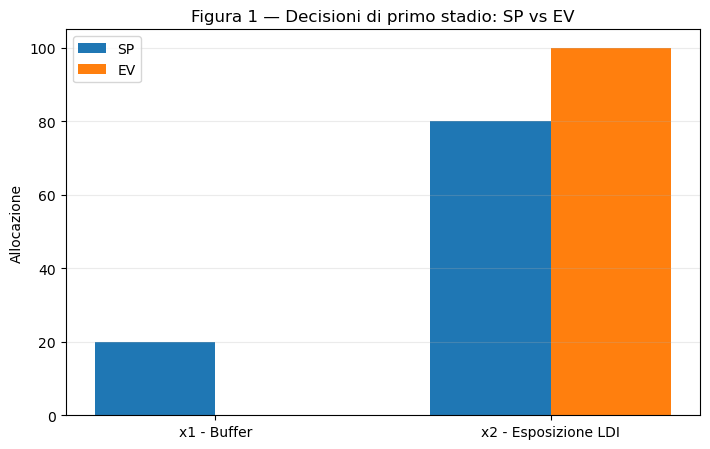

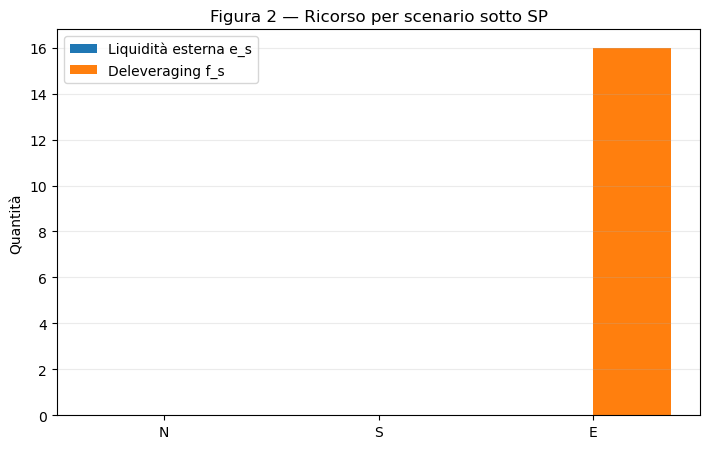

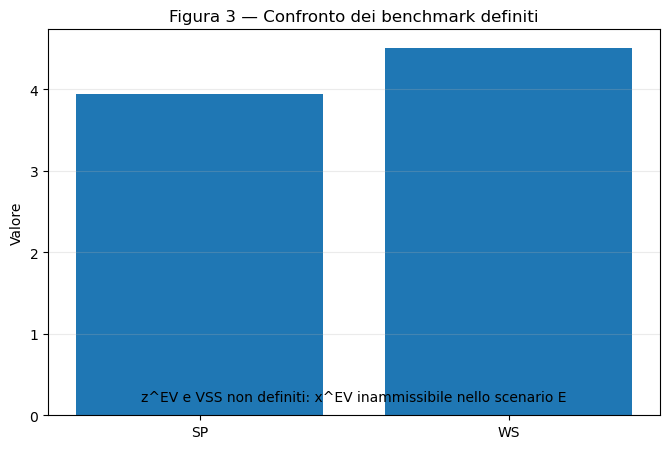

### Controlli conclusivi

,Controllo,Esito
0,Somma probabilità = 1,True
1,Bilancio iniziale SP,True
2,x2_SP >= 50,True
3,e_SP nei limiti,True
4,f_SP nei limiti,True
5,f_SP <= x2_SP,True
6,Bilanci SP,True
7,xEV mantenuta fissa nella rivalutazione,True
8,EV ammissibile in N,True
9,EV ammissibile in S,True


Tutti i controlli conclusivi sono soddisfatti.


In [6]:
# Tabella 5: solo benchmark numericamente definiti.
benchmark_rows = [
    {"Benchmark": "SP", "Valore": z_sp, "Stato": "Definito"},
    {"Benchmark": "WS", "Valore": z_ws, "Stato": "Definito"},
    {"Benchmark": "EVPI", "Valore": evpi, "Stato": "Definito"},
]

if z_ev is not None:
    benchmark_rows.insert(0, {"Benchmark": "EV rivalutato", "Valore": z_ev, "Stato": "Definito"})
    benchmark_rows.append({"Benchmark": "VSS", "Valore": vss, "Stato": "Definito"})
else:
    benchmark_rows.append({
        "Benchmark": "EV rivalutato / VSS",
        "Valore": np.nan,
        "Stato": "Non definiti: x^EV è inammissibile nello scenario E"
    })

tab5 = pd.DataFrame(benchmark_rows)

display(Markdown("### Tabella 5 — Confronto dei benchmark"))
display(tab5)

# Figura 1 — decisioni di primo stadio
pos = np.arange(2)
width = 0.36

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.bar(pos - width/2, x_sp, width, label="SP")
ax.bar(pos + width/2, x_ev, width, label="EV")
ax.set_xticks(pos)
ax.set_xticklabels(["x1 - Buffer", "x2 - Esposizione LDI"])
ax.set_ylabel("Allocazione")
ax.set_title("Figura 1 — Decisioni di primo stadio: SP vs EV")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Figura 2 — ricorso sotto SP
pos = np.arange(n_s)

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.bar(pos - width/2, e_sp, width, label="Liquidità esterna e_s")
ax.bar(pos + width/2, f_sp, width, label="Deleveraging f_s")
ax.set_xticks(pos)
ax.set_xticklabels(scenarios)
ax.set_ylabel("Quantità")
ax.set_title("Figura 2 — Ricorso per scenario sotto SP")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Figura 3 — benchmark definiti
bench_labels = ["SP", "WS"]
bench_values = [z_sp, z_ws]

if z_ev is not None:
    bench_labels = ["EV", "SP", "WS"]
    bench_values = [z_ev, z_sp, z_ws]

fig, ax = plt.subplots(figsize=(6.8, 4.6))
ax.bar(bench_labels, bench_values)
ax.set_ylabel("Valore")
ax.set_title("Figura 3 — Confronto dei benchmark definiti")
ax.grid(axis="y", alpha=0.25)

if z_ev is None:
    ax.text(
        0.5, 0.03,
        "z^EV e VSS non definiti: x^EV inammissibile nello scenario E",
        transform=ax.transAxes, ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

# Controlli conclusivi
controls = pd.DataFrame({
    "Controllo": [
        "Somma probabilità = 1",
        "Bilancio iniziale SP",
        "x2_SP >= 50",
        "e_SP nei limiti",
        "f_SP nei limiti",
        "f_SP <= x2_SP",
        "Bilanci SP",
        "xEV mantenuta fissa nella rivalutazione",
        "EV ammissibile in N",
        "EV ammissibile in S",
        "EV inammissibile in E",
        "zEV non definito se EV non è ammissibile in tutti gli scenari",
        "VSS non definito se EV non è ammissibile in tutti gli scenari",
        "Problemi WS separati e risolti",
        "zSP <= zWS",
        "EVPI >= 0",
    ],
    "Esito": [
        np.isclose(p.sum(), 1.0),
        np.isclose(x_sp.sum(), A0),
        x_sp[1] >= X2_MIN - 1e-9,
        np.all((e_sp >= -1e-9) & (e_sp <= E_MAX + 1e-9)),
        np.all((f_sp >= -1e-9) & (f_sp <= F_MAX + 1e-9)),
        np.all(f_sp <= x_sp[1] + 1e-9),
        np.max(np.abs(balance_residual_sp)) < 1e-8,
        all(np.isclose(row["x1_EV"], x_ev[0]) and np.isclose(row["x2_EV"], x_ev[1])
            for _, row in tab3_eval.iterrows()),
        ev_recourse_results[0].success,
        ev_recourse_results[1].success,
        not ev_recourse_results[2].success,
        z_ev is None,
        vss is None,
        all(r.success for r in ws_results),
        z_sp <= z_ws + 1e-9,
        evpi >= -1e-9,
    ],
})

display(Markdown("### Controlli conclusivi"))
display(controls)

if not controls["Esito"].all():
    raise AssertionError("Almeno un controllo conclusivo non è soddisfatto.")

print("Tutti i controlli conclusivi sono soddisfatti.")

# Interpretazione finanziaria docente di riferimento

La soluzione stocastica sceglie un buffer iniziale che rende ammissibile il ricorso in tutti gli scenari assegnati. Il buffer non è quindi soltanto una scelta prudenziale: nel modello svolge una funzione diretta di **fattibilità**.

La decisione Expected Value è ottenuta sostituendo gli scenari con parametri medi. Essa può apparire più redditizia nel problema deterministico medio, ma la sua rivalutazione negli scenari originari mostra il limite della mediazione: se la capacità di ricorso disponibile nello scenario estremo non è sufficiente, la decisione non appartiene al dominio della funzione di ricorso in quello scenario.

In tale situazione:

- il valore ottimo del problema deterministico medio resta perfettamente definito;
- \(x^{EV}\) resta una decisione ben definita;
- la rivalutazione di \(x^{EV}\) nel problema stocastico originario fallisce nello scenario inammissibile;
- \(z^{EV}\) non è definito nella forma standard;
- il VSS non deve essere prodotto artificialmente.

L'EVPI resta invece definito perché confronta la soluzione stocastica con il benchmark wait-and-see, entrambi ammissibili.

Il benchmark WS non è implementabile ex ante: consente di scegliere una diversa decisione iniziale dopo avere osservato anticipatamente lo scenario e serve esclusivamente a misurare il valore dell'informazione perfetta.

# Limiti del modello

Il caso è deliberatamente stilizzato e non costituisce una ricostruzione quantitativa di uno specifico fondo pensione o portafoglio LDI.

Il modello non rappresenta:

- dinamiche intraday;
- collateral waterfall;
- haircut multipli;
- feedback endogeni sui prezzi dei gilt;
- derivati specifici;
- duration delle passività;
- requisiti regolamentari dettagliati;
- informazione progressiva;
- decisioni multistadio.

La struttura resta esclusivamente **two-stage**.

# Sintesi finale

Il notebook implementa il Caso TakeHome della Lezione 16 nel framework **two-stage** richiesto:

- un'unica decisione iniziale \(x\) comune agli scenari;
- ricorso scenario-specifico \((e_s,f_s,g_s)\);
- capacità di ricorso limitata;
- soluzione SP;
- problema EV e rivalutazione scenario per scenario;
- riconoscimento esplicito dell'inammissibilità di \(x^{EV}\) nello scenario estremo;
- nessuna produzione artificiale di \(z^{EV}\) o VSS;
- tre problemi WS separati;
- \(z^{WS}\) ed EVPI;
- cinque tabelle;
- tre grafici;
- controlli numerici e logici conclusivi.

Gli output computazionali sono prodotti direttamente nel notebook e non vengono esportati automaticamente in file esterni.